# NB 02 · Scénario 1 : Scan et inventaire

**Situation :** l'état-major veut un **état des lieux instantané** du théâtre GOLFE : qui agit, avec quels moyens, où, et dans quelles opérations. Personne n'a le temps de lire 2 200 articles.

**Le parallèle avec God's Eye :** YOLO repérait des *avions* et des *navires* sur une image satellite. Ici, un modèle de **NER** (*Named Entity Recognition*, reconnaissance d'entités nommées) repère des *personnes*, des *forces armées* et des *armements* dans du texte. Le livrable est le même : un **rapport d'inventaire**.

**Le pipeline :**
1. **Modèle généraliste** (spaCy `en_core_web_sm`, qui tourne sur processeur, sans GPU) : il connaît les personnes, organisations et lieux.
2. **Lexique militaire** : il comble les angles morts du modèle (armements, sites stratégiques, navires, opérations).
3. **Scan** du corpus complet.
4. **Consolidation** : « Trump », « Donald Trump » et « President Trump » doivent compter pour une seule personne.
5. **Rapport d'inventaire**, puis **fiche de situation**, puis **recoupement avec la vérité terrain**.

| Catégorie | Exemples |
|---|---|
| PERSONNE | Donald Trump, Abbas Araghchi |
| ORGANISATION | White House, IAEA, UN Security Council |
| LIEU | Iran, Tehran, Middle East |
| FORCE_ARMEE | IRGC, CENTCOM, Hezbollah |
| ARMEMENT | GBU-57, Shahed, ballistic missile |
| SITE_STRATEGIQUE | Fordow, Natanz, Strait of Hormuz |
| NAVIRE | USS Abraham Lincoln, oil tanker |
| OPERATION | Operation Midnight Hammer, Operation Epic Fury |

> Avant la première exécution, installe le modèle anglais : `python -m spacy download en_core_web_sm`

In [1]:
import sys
from pathlib import Path

# On retrouve la racine du projet (le dossier qui contient data_lake/) pour importer src/
RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_lake").is_dir())
sys.path.insert(0, str(RACINE / "src"))

import re
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spacy
from IPython.display import HTML, display
from spacy import displacy

from spirit_digger.config import OUTPUTS
from spirit_digger.lexique_militaire import NAVIRES_ATTAQUES_TERRAIN, ajouter_lexique, canonique
from spirit_digger.style import ACCENT, ALERTE, FOND, OK, PANNEAU, TEXTE, VEILLE, bandeau, theme_ops

theme_ops()
bandeau("NB 02 · Scan et inventaire", "Théâtre GOLFE : qui, avec quoi, où, dans quelle opération ?")

corpus = pd.read_parquet(OUTPUTS / "corpus_golfe.parquet")
print(corpus["langue"].value_counts().to_dict())
corpus = corpus[corpus["langue"] == "en"].reset_index(drop=True)
print(f"{len(corpus)} articles en anglais retenus (le modèle est anglophone)")

{'en': 2196, 'id': 35}
2196 articles en anglais retenus (le modèle est anglophone)


## 1. Le modèle généraliste et ses angles morts

On teste d'abord le modèle « sorti de la boîte » sur une phrase type.

In [2]:
nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])
nlp.enable_pipe("senter")  # découpage en phrases, léger et rapide

PHRASE_TEST = ("The IRGC closed the Strait of Hormuz after Donald Trump ordered B-2 bombers to drop "
               "GBU-57 bunker busters on Fordow during Operation Midnight Hammer, while the "
               "USS Abraham Lincoln moved into the Gulf of Oman.")

displacy.render(nlp(PHRASE_TEST), style="ent", jupyter=True)

**Ce qui manque :** les armements (B-2, GBU-57) sont ignorés, et **Fordow**, un site nucléaire enterré, n'est pas reconnu comme tel. Le nom de l'opération et celui du navire ne sont pas typés militairement. Le modèle a été entraîné sur de l'actualité générale, pas sur des rapports militaires.

## 2. Ajout du lexique militaire

On insère un **EntityRuler** *avant* le modèle statistique : les termes métier sont reconnus en priorité, et le modèle complète le reste. Le lexique est dans [`src/spirit_digger/lexique_militaire.py`](../src/spirit_digger/lexique_militaire.py), tu peux l'enrichir librement.

In [3]:
nlp = ajouter_lexique(nlp)
print("Chaîne de traitement :", " → ".join(nlp.pipe_names))

COULEURS_NER = {"FORCE_ARMEE": "#ff4d5e", "ARMEMENT": "#ffb020", "SITE_STRATEGIQUE": "#7c5cff",
                "NAVIRE": "#4cc3ff", "OPERATION": "#ff7ad9", "AGENCE_INTERNATIONALE": "#2bd99f"}
displacy.render(nlp(PHRASE_TEST), style="ent", jupyter=True, options={"colors": COULEURS_NER})

Chaîne de traitement : tok2vec → tagger → senter → attribute_ruler → entity_ruler → ner


Même test sur un **vrai article** du corpus :

In [4]:
exemple = corpus[corpus["texte"].str.contains("Midnight Hammer") & corpus["texte"].str.contains("Fordow")].iloc[0]
print(f"{exemple.source} · {exemple.titre}\n")
displacy.render(nlp(exemple.texte[:1200]), style="ent", jupyter=True, options={"colors": COULEURS_NER})

The Jakarta Post · The shadow of Fordow: Navigating nuclear stability in a multipolar world



## 3. Scan du corpus complet

Le scan prend environ 3 à 4 minutes sur processeur. Le résultat est **mis en cache** dans `outputs/` : les exécutions suivantes sont instantanées. Le cache est refait automatiquement si le corpus du NB 01 a changé. Mets `FORCER_SCAN = True` si tu modifies le lexique.

On garde, pour chaque entité, l'article et **la phrase** où elle apparaît. Le NB 04 s'en servira pour relier les acteurs cités ensemble.

In [5]:
FORCER_SCAN = False
CACHE = OUTPUTS / "cache_ner_golfe.parquet"
LABELS_UTILES = {"PERSON", "ORG", "GPE", "LOC", "FAC", "FORCE_ARMEE", "ARMEMENT",
                 "SITE_STRATEGIQUE", "NAVIRE", "OPERATION", "AGENCE_INTERNATIONALE"}

cache_valide = CACHE.exists() and CACHE.stat().st_mtime > (OUTPUTS / "corpus_golfe.parquet").stat().st_mtime

if cache_valide and not FORCER_SCAN:
    brut = pd.read_parquet(CACHE)
    print(f"Cache chargé : {len(brut):,} mentions")
else:
    debut = time.time()
    textes = (corpus["titre"] + ". " + corpus["texte"].str[:10_000]).tolist()
    lignes = []
    for i, (doc_id, doc) in enumerate(zip(corpus["doc_id"], nlp.pipe(textes, batch_size=64))):
        for num_phrase, phrase in enumerate(doc.sents):
            for ent in phrase.ents:
                if ent.label_ in LABELS_UTILES:
                    lignes.append((doc_id, num_phrase, ent.text, ent.label_))
        if i % 500 == 0:
            print(f"  {i:>5} / {len(textes)} articles · {time.time() - debut:.0f} s")
    brut = pd.DataFrame(lignes, columns=["doc_id", "phrase", "brut", "label_spacy"])
    brut.to_parquet(CACHE, index=False)
    print(f"Scan terminé en {time.time() - debut:.0f} s : {len(brut):,} mentions")

brut["label_spacy"].value_counts()

Cache chargé : 85,891 mentions


label_spacy
GPE                      41846
ORG                      17019
PERSON                   16689
SITE_STRATEGIQUE          2898
LOC                       2719
FORCE_ARMEE               2063
ARMEMENT                  1093
FAC                        589
NAVIRE                     554
AGENCE_INTERNATIONALE      294
OPERATION                  127
Name: count, dtype: int64

## 4. Consolidation : du brut au renseignement

Le brut est inexploitable tel quel. Cinq corrections, celles qu'un analyste ferait à la main :

1. **Forme canonique** : on retire articles, titres et possessifs, puis on unifie les alias (« Ayatollah Ali Khamenei » devient « Ali Khamenei », « the US » devient « United States »).
2. **Vote majoritaire sur la catégorie** : le modèle classe parfois « Trump » comme organisation. On garde la catégorie la plus fréquente pour chaque entité.
3. **Translittération** : « Ghalibaf » et « Qalibaf » sont la même personne.
4. **Résolution des noms de famille** : « Trump » seul devient « Donald Trump »… **mais attention** : « Khamenei » seul peut désigner **Ali** Khamenei (le Guide suprême, tué le 28/02 d'après nos sources) **ou** son fils **Mojtaba**, présenté comme son successeur. On résout donc *d'abord dans l'article* (quel Khamenei a été nommé en entier dans ce texte ?), et au niveau global seulement si un nom domine nettement.
5. **Suppression du bruit** : les médias qui se citent eux-mêmes (« BBC », « Reuters ») et quelques faux positifs.

In [6]:
CATEGORIE = {"PERSON": "PERSONNE", "ORG": "ORGANISATION", "AGENCE_INTERNATIONALE": "ORGANISATION",
             "GPE": "LIEU", "LOC": "LIEU", "FAC": "LIEU"}
ent = brut.copy()
ent["entite"] = ent["brut"].map(canonique)
ent["categorie"] = ent["label_spacy"].map(lambda l: CATEGORIE.get(l, l))

# Résidus de mise en page web collés à un nom (« Donald Trump Follow Donald Trump », « BST Donald Trump »)
MOTS_PARASITES = {"Follow", "BST", "GMT", "Warns", "Says", "Live", "Watch", "Updates", "Advertisement", "Commissioning"}
parasite = ent["entite"].str.split().map(lambda mots: bool(set(mots) & MOTS_PARASITES) or len(mots) > 5)
print(f"{parasite.sum()} mentions parasites retirées, ex. : {ent.loc[parasite, 'entite'].value_counts().head(3).index.tolist()}")
ent = ent[~parasite]


# 2. vote majoritaire. Exception : le modèle confond souvent un pays et son gouvernement (« UAE said… »).
#    Si une entité est vue comme LIEU dans au moins 30 % des cas, c'est un LIEU.
def voter(categories):
    parts = categories.value_counts(normalize=True)
    return "LIEU" if parts.get("LIEU", 0) >= 0.3 and parts.index[0] in {"ORGANISATION", "PERSONNE"} else parts.index[0]


vote = ent.groupby("entite")["categorie"].agg(voter)
avant = ent.loc[ent["entite"] == "Trump", "categorie"].value_counts().to_dict()
ent["categorie"] = ent["entite"].map(vote)
print("« Trump » avant le vote :", avant, "→ après :", vote.get("Trump"))

554 mentions parasites retirées, ex. : ['BST', 'GMT', 'Donald Trump Follow Donald Trump']


« Trump » avant le vote : {'PERSONNE': 1670, 'ORGANISATION': 1647} → après : PERSONNE


**Le piège de la translittération.** Les noms persans et arabes s'écrivent de plusieurs façons en alphabet latin : le président du Parlement iranien apparaît comme *Ghalibaf*, *Qalibaf*, *Mohammad Baqer*, *Mohammad-Bagher*… Pour la machine, ce sont des personnes différentes. On calcule donc une **clé phonétique** : gh ≈ q, kh ≈ k, ae ≈ a, ou ≈ u, lettres doublées simplifiées. Toutes les variantes qui partagent la même clé sont fusionnées sous l'orthographe la plus fréquente.

In [7]:
def cle_phonetique(nom):
    k = nom.lower().replace("-", " ")
    for a, b in [("gh", "q"), ("kh", "k"), ("ae", "a"), ("ei", "i"), ("ou", "u"), ("ee", "i")]:
        k = k.replace(a, b)
    return re.sub(r"(.)\1", r"\1", k)                 # lettres doublées : Massoud → Masud


pers = ent["categorie"] == "PERSONNE"
cles = ent.loc[pers, "entite"].map(cle_phonetique)
frequence = ent.loc[pers].groupby("entite")["doc_id"].nunique()
groupes = pd.DataFrame({"entite": ent.loc[pers, "entite"], "cle": cles}).drop_duplicates()
groupes["articles"] = groupes["entite"].map(frequence)
retenue = groupes.sort_values("articles", ascending=False).drop_duplicates("cle").set_index("cle")["entite"]
ent.loc[pers, "entite"] = cles.map(retenue)

fusions = groupes[groupes.groupby("cle")["entite"].transform("nunique") > 1].copy()
fusions["fusionné en"] = fusions["cle"].map(retenue)
fusions = (fusions.groupby("fusionné en")
                  .agg(variantes=("entite", lambda s: " · ".join(sorted(s))), articles=("articles", "sum"))
                  .sort_values("articles", ascending=False))
print(f"{len(fusions)} personnes avaient plusieurs orthographes :")
fusions.head(8)

50 personnes avaient plusieurs orthographes :


,variantes,articles
fusionné en,,
Donald Trump,DONALD TRUMP · Donald Trump,739
Abbas Araghchi,Abbas Araghchi · Abbas Araqchi,129
Esmaeil Baghaei,Esmaeil Baghaei · Esmaeil Baqaei · Esmaeil Baq...,69
Mohammad Bagher Ghalibaf,Mohammad Bagher Ghalibaf · Mohammad Bagher Qal...,63
Masoud Pezeshkian,Masoud Pezeshkian · Massoud Pezeshkian,60
Ghalibaf,Ghalibaf · Qalibaf,27
Volodymyr Zelensky,Volodymyr Zelensky · Volodymyr Zelenskyy,19
Bashar al-Assad,Bashar al Assad · Bashar al-Assad,11


In [8]:
# 4. résolution des noms de famille
pers = ent["categorie"] == "PERSONNE"
complets = ent.loc[pers & ent["entite"].str.contains(" "), ["doc_id", "entite"]].drop_duplicates()
complets["nom"] = complets["entite"].str.split().str[-1]

par_article = complets.groupby(["doc_id", "nom"])["entite"].agg(set)          # noms complets cités dans chaque article
popularite = complets.groupby(["nom", "entite"]).size()                         # nb d'articles par nom complet
NOMS_CONNUS = set(popularite.index.get_level_values(0))


def resoudre(doc_id, nom):
    candidats = par_article.get((doc_id, nom))
    if candidats and len(candidats) == 1:            # un seul « X Khamenei » dans cet article : c'est lui
        return next(iter(candidats))
    if nom in NOMS_CONNUS:
        parts = popularite[nom] / popularite[nom].sum()
        if parts.max() >= 0.8:                       # un nom complet domine nettement dans tout le corpus
            return parts.idxmax()
    return nom                                       # ambigu : on ne devine pas


seuls = pers & ~ent["entite"].str.contains(" ")
ent.loc[seuls, "entite"] = [resoudre(d, n) for d, n in zip(ent.loc[seuls, "doc_id"], ent.loc[seuls, "entite"])]

for nom in ["Khamenei", "Trump", "Netanyahu"]:
    print(f"{nom:<10} → {popularite[nom].sort_values(ascending=False).head(3).to_dict()}")
print(f"\n« Khamenei » encore ambigu dans {(ent['entite'] == 'Khamenei').sum()} mentions (articles sans nom complet)")

Khamenei   → {'Ali Khamenei': 192, 'Mojtaba Khamenei': 105, 'Mojtaba Hosseini Khamenei': 2}
Trump      → {'Donald Trump': 739, 'Lara Trump': 3, 'Donald J. Trump': 3}
Netanyahu  → {'Benjamin Netanyahu': 191, 'Binyamin Netanyahu': 1, 'X. Netanyahu': 1}

« Khamenei » encore ambigu dans 165 mentions (articles sans nom complet)


In [9]:
# 5. bruit
MEDIAS = set(corpus["source"].str.lower()) | {"reuters", "ap", "afp", "associated press", "bbc", "cnn", "getty images",
                                              "bbc news", "al jazeera", "dw", "the guardian", "x"}
MEDIAS |= {m.removeprefix("the ") for m in MEDIAS}   # « The Independent » est extrait comme « Independent »
FAUX_POSITIFS = {"supreme", "state", "share", "exclusive", "tempo", "watch", "live", "read more", "copy link",
                 "supreme leader", "brent", "bitcoin", "btc", "ethereum", "crypto",   # titres, indices boursiers, crypto
                 "producer", "email", "writing", "defense", "defence", "ap news", "google add ap news",
                 "thomson reuters trust principles", "inside washington", "ai", "tempo.co", "google news",
                 "editor", "newscast", "iranian", "islamic",
                 "google", "times", "telegraph"}  # « Suivez-nous sur Google News », menus de journaux                         # crédits, menus, adjectifs mal typés
ent = ent[~ent["entite"].str.lower().isin(MEDIAS | FAUX_POSITIFS) & (ent["entite"].str.len() > 1)]

ent = ent.merge(corpus[["doc_id", "date", "source"]], on="doc_id")
ent[["doc_id", "date", "source", "phrase", "entite", "categorie", "brut"]].to_parquet(OUTPUTS / "entites_golfe.parquet", index=False)
print(f"{len(ent):,} mentions consolidées · {ent['entite'].nunique():,} entités distinctes → entites_golfe.parquet")

82,192 mentions consolidées · 10,986 entités distinctes → entites_golfe.parquet


## 5. Rapport d'inventaire

Comme le rapport de God's Eye : chaque catégorie avec ses éléments les plus présents. La mesure est le **nombre d'articles** qui citent l'entité, et non le nombre de mentions : un seul article qui répète 30 fois un nom ne doit pas fausser le tableau.

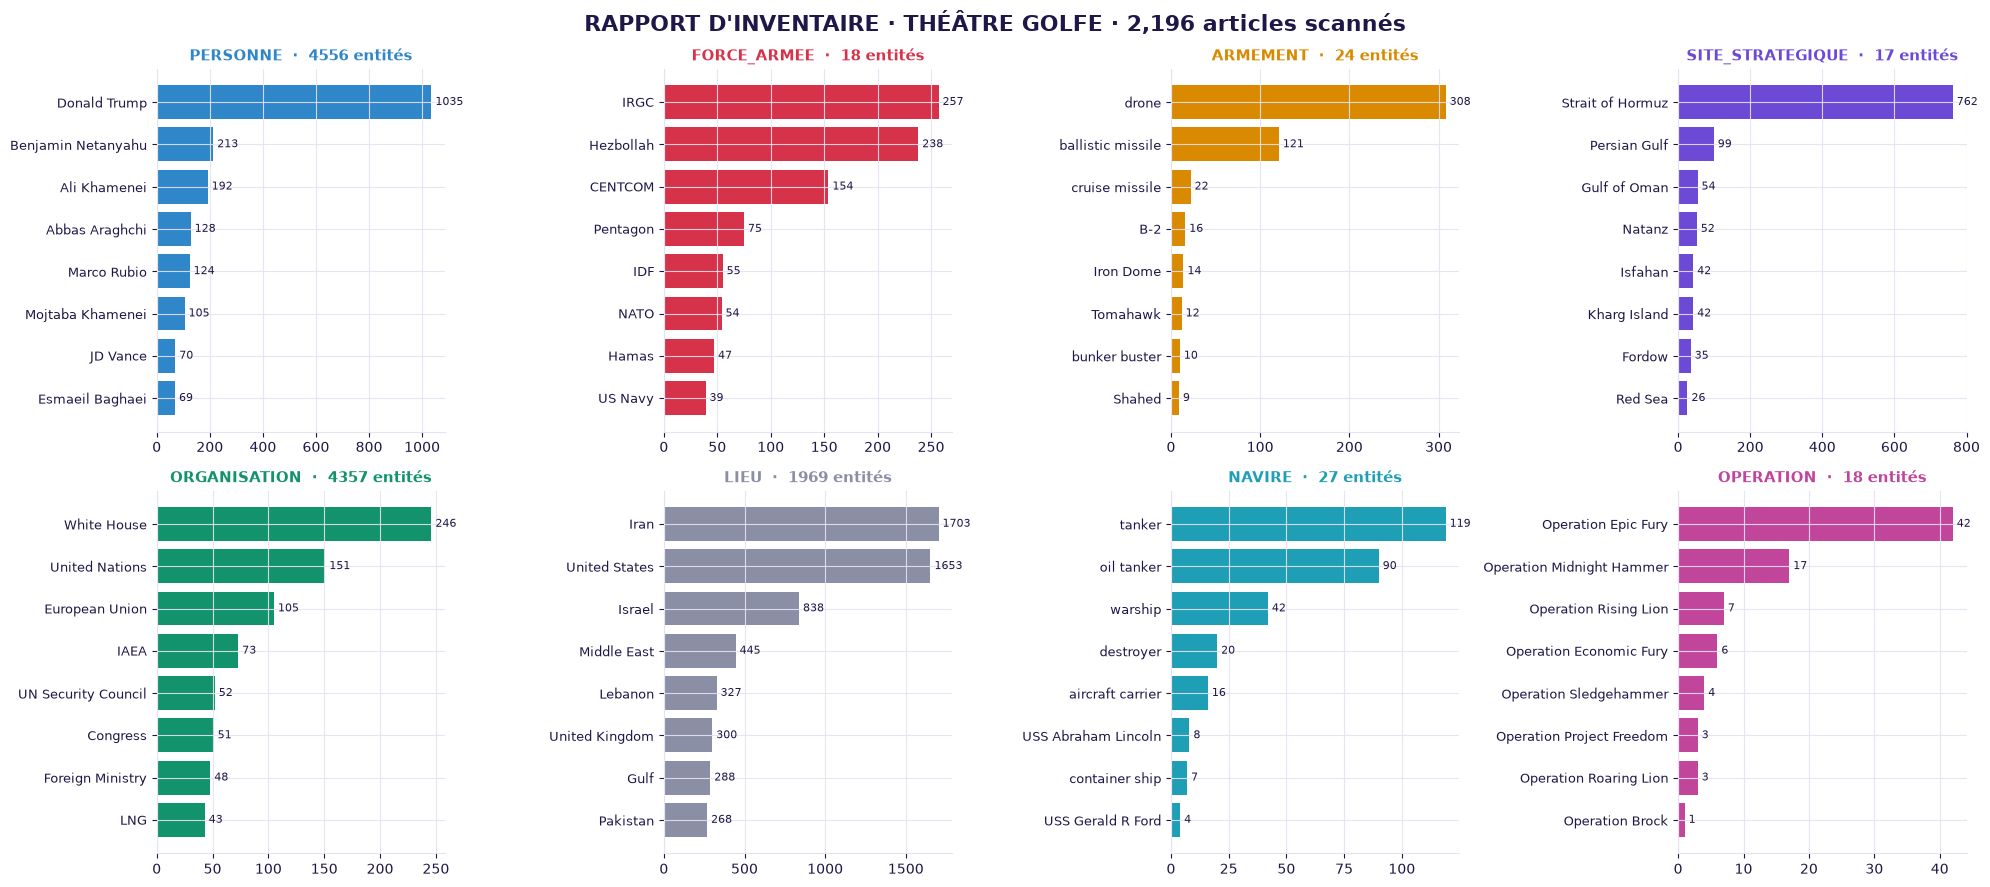

In [10]:
ORDRE = ["PERSONNE", "FORCE_ARMEE", "ARMEMENT", "SITE_STRATEGIQUE",
         "ORGANISATION", "LIEU", "NAVIRE", "OPERATION"]
COULEUR_CAT = {"PERSONNE": "#2f86c9", "FORCE_ARMEE": ALERTE, "ARMEMENT": VEILLE, "SITE_STRATEGIQUE": ACCENT,
               "ORGANISATION": OK, "LIEU": "#8a8fa6", "NAVIRE": "#1f9fb5", "OPERATION": "#c2459c"}

inventaire = (ent.groupby(["categorie", "entite"])["doc_id"].nunique()
                 .rename("articles").reset_index()
                 .sort_values(["categorie", "articles"], ascending=[True, False]))
inventaire.to_csv(OUTPUTS / "inventaire_golfe.csv", index=False)

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, cat in zip(axes.flat, ORDRE):
    top = inventaire[inventaire["categorie"] == cat].head(8).iloc[::-1]
    ax.barh(top["entite"], top["articles"], color=COULEUR_CAT[cat])
    n = (inventaire["categorie"] == cat).sum()
    ax.set_title(f"{cat}  ·  {n} entités", color=COULEUR_CAT[cat], fontsize=11)
    ax.tick_params(axis="y", labelsize=9)
    for y, v in enumerate(top["articles"]):
        ax.text(v, y, f" {v}", va="center", fontsize=8)
fig.suptitle(f"RAPPORT D'INVENTAIRE · THÉÂTRE GOLFE · {len(corpus):,} articles scannés", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUTS / "02_rapport_inventaire.png", dpi=130)
plt.show()

## 6. Fiche de situation

Le même renseignement, au format qu'un officier lit en 30 secondes.

In [11]:
def ligne(cat, n=5):
    top = inventaire[inventaire["categorie"] == cat].head(n)
    return " · ".join(f"<b>{e}</b> <span style='opacity:.6'>({a})</span>" for e, a in zip(top.entite, top.articles))


ops = (ent[ent["categorie"] == "OPERATION"].groupby("entite")
          .agg(articles=("doc_id", "nunique"), premiere=("date", "min")).sort_values("articles", ascending=False))
ops_html = "".join(
    f"<li><b>{nom}</b> · {r.articles} articles"
    f"{' · première mention datée ' + r.premiere.strftime('%d/%m/%Y') if pd.notna(r.premiere) else ''}</li>"
    for nom, r in ops[ops["articles"] >= 2].iterrows())

periode = corpus["date"].dropna()
display(HTML(f"""
<div style="background:{FOND};color:{TEXTE};font-family:monospace;padding:18px 22px;border:1px solid {ACCENT};border-radius:8px">
  <div style="color:{ACCENT};letter-spacing:3px;font-size:11px">FICHE DE SITUATION // THÉÂTRE GOLFE // EXERCICE</div>
  <div style="font-size:12px;opacity:.7;margin:4px 0 14px">{len(corpus):,} articles · {corpus['source'].nunique()} médias ·
       période datée {periode.min():%d/%m/%Y} → {periode.max():%d/%m/%Y}</div>
  <p><span style="color:#2f86c9">▌ ACTEURS CLÉS</span><br>{ligne("PERSONNE")}</p>
  <p><span style="color:{ALERTE}">▌ FORCES EN PRÉSENCE</span><br>{ligne("FORCE_ARMEE")}</p>
  <p><span style="color:{VEILLE}">▌ MOYENS CITÉS</span><br>{ligne("ARMEMENT")}</p>
  <p><span style="color:{ACCENT}">▌ SITES SENSIBLES</span><br>{ligne("SITE_STRATEGIQUE")}</p>
  <p><span style="color:#1f9fb5">▌ MOYENS NAVALS</span><br>{ligne("NAVIRE")}</p>
  <p><span style="color:#c2459c">▌ OPÉRATIONS IDENTIFIÉES</span></p><ul style="margin-top:0">{ops_html}</ul>
</div>"""))

## 7. Chronologie : qui monte, qui descend ?

Un tiers seulement des articles est daté, mais ça suffit pour voir la dynamique de mai-juin 2026. Chaque case donne le nombre d'articles de la semaine qui citent l'acteur.

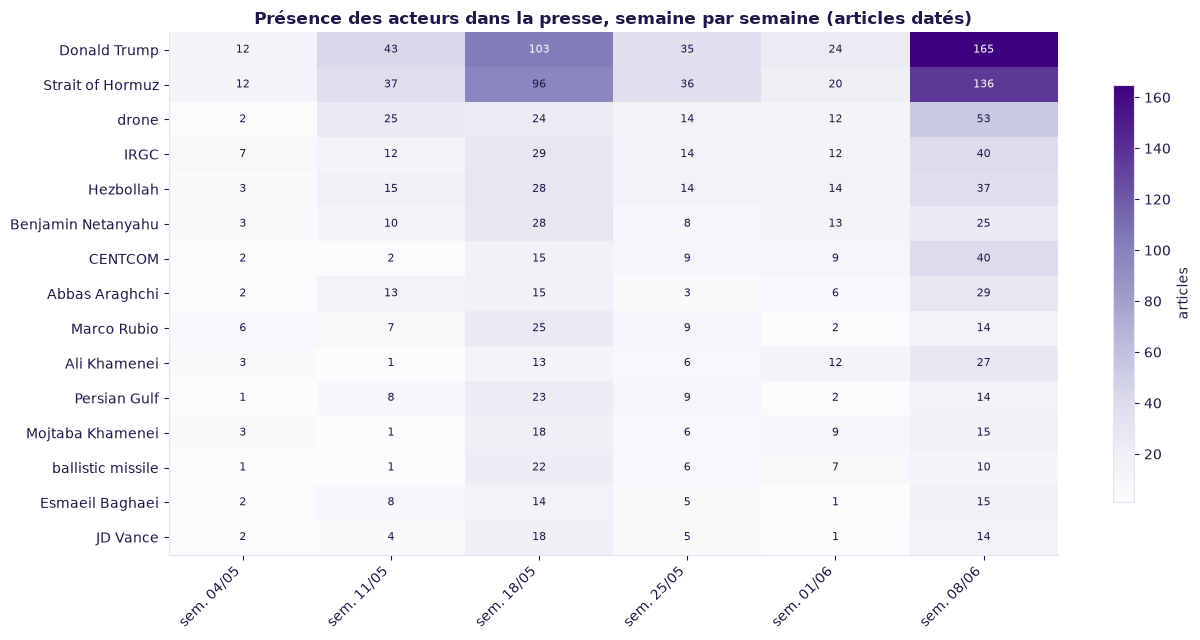

In [12]:
CATS_ACTEURS = ["PERSONNE", "FORCE_ARMEE", "SITE_STRATEGIQUE", "ARMEMENT"]
dates = ent.dropna(subset=["date"])
dates = dates[(dates["date"] >= "2026-05-01") & dates["categorie"].isin(CATS_ACTEURS)]
top_acteurs = dates.groupby("entite")["doc_id"].nunique().sort_values(ascending=False).head(15).index

grille = (dates[dates["entite"].isin(top_acteurs)]
             .groupby([pd.Grouper(key="date", freq="W-MON", label="left"), "entite"])["doc_id"].nunique()
             .unstack(fill_value=0).T.loc[top_acteurs])

fig, ax = plt.subplots(figsize=(13, 6.5))
im = ax.imshow(grille.values, cmap="Purples", aspect="auto")
ax.set_yticks(range(len(grille)), grille.index)
ax.set_xticks(range(grille.shape[1]), [f"sem. {d:%d/%m}" for d in grille.columns], rotation=45, ha="right")
ax.grid(False)
for (y, x), v in np.ndenumerate(grille.values):
    if v:
        ax.text(x, y, v, ha="center", va="center", fontsize=8, color="white" if v > grille.values.max() * 0.6 else TEXTE)
ax.set_title("Présence des acteurs dans la presse, semaine par semaine (articles datés)")
plt.colorbar(im, ax=ax, label="articles", shrink=0.8)
plt.tight_layout()
plt.show()

## 8. Recoupement avec la vérité terrain

Le journal de bord d'Ormuz recense **13 navires attaqués** (février à mai 2026). Combien d'entre eux la presse du corpus nomme-t-elle ? C'est une question classique d'analyste : **qu'est-ce que mes sources ne voient pas ?**

In [13]:
texte_complet = corpus["titre"] + " " + corpus["texte"]
hz = pd.read_parquet(OUTPUTS / "verite_terrain_hormuz.parquet")

couverture = pd.DataFrame([{
    "navire": nom,
    "date_incident (terrain)": hz.loc[hz["key_event"].str.contains(nom, regex=False), "date"].min(),
    "articles qui le nomment": texte_complet.str.contains(rf"\b{nom}\b", regex=True).sum(),
} for nom in NAVIRES_ATTAQUES_TERRAIN]).sort_values("date_incident (terrain)")

vus = (couverture["articles qui le nomment"] > 0).sum()
print(f"La presse nomme {vus} des {len(couverture)} navires attaqués.")
couverture.style.map(lambda v: f"color:{ALERTE if v == 0 else OK};font-weight:bold", subset=["articles qui le nomment"])

La presse nomme 2 des 13 navires attaqués.


,navire,date_incident (terrain),articles qui le nomment
11,Iron Maiden,2026-03-04 00:00:00,0
12,Bogazici,2026-03-05 00:00:00,0
0,Safeen Prestige,2026-03-06 00:00:00,0
1,Prima,2026-03-07 00:00:00,0
2,Louis P,2026-03-07 00:00:00,0
3,Mayuree Naree,2026-03-11 00:00:00,0
10,Express Rome,2026-03-30 00:00:00,0
4,Al Salmi,2026-03-31 00:00:00,0
5,Aqua 1,2026-04-01 00:00:00,0
6,MSC Ishyka,2026-04-04 00:00:00,0


**Lecture analyste :** la presse généraliste parle *du* détroit, mais presque jamais *des* navires. Pour suivre les incidents maritimes, il faudrait d'autres sources : AIS (positions des navires), Lloyd's List, avis UKMTO. **C'est un angle mort à signaler dans le bulletin.**

> « Prima » est aussi un mot courant : le seul article qui « le nomme » est peut-être un faux positif. Un analyste vérifie toujours à la main un résultat aussi faible.

## Ce qu'il faut retenir

- **Modèle généraliste et lexique métier** : la combinaison fait apparaître des opérations (Epic Fury, Midnight Hammer), des armements (GBU-57, Shahed) et des navires (USS Abraham Lincoln) que le modèle seul ignorait.
- **La consolidation fait la valeur** : vote majoritaire, alias, résolution prudente des noms de famille (le piège Ali / Mojtaba Khamenei).
- **Le recoupement terrain** révèle un angle mort : la presse ne nomme presque aucun navire attaqué.
- **Limites, à dire en démo :** modèle `sm` (le plus léger), anglais uniquement (les 36 articles indonésiens sont écartés), deux tiers des articles sans date.

> **Phrase de démo :** « En 4 minutes sur un simple ordinateur portable, Spirit Digger a scanné 2 200 articles et inventorié les acteurs, les forces, les armements, les sites et les opérations du théâtre. Il a aussi signalé ce que la presse ne voit pas. »

**Prochaine étape → NB 03 : alerte précoce sur le théâtre UKRAINE.**